# 10 · More data: all 790 questions, 5 answers each
Notebook 09 trained on 425 answers, and the conclusion was that more data, not a different model, is the next lever. This notebook reruns notebook 09's parts A–D on dataset v2 (`src/expand.py`):
- **Questions:** all 790 TruthfulQA questions (ids T001–T790), not a sample of 500.
- **Answers:** 5 sampled answers per question at temperature 0.7, about 3,950 in total.
- **Grades:** every answer graded by Claude, as in step 2c.
- **Features:** last-token and mean-token hidden states at every layer, plus uncertainty features, from one forward pass per answer (`data/v2/features/`, gitignored).

Splits are assigned per question (70/15/15 of 790 questions), so all 5 answers to a question are in the same group, and CV folds are grouped by question too. Because the data is about 8 times larger, CV uses one round instead of three. Everything else (models, settings grids, layer window 18–36, accuracy at p > 0.5) is identical to notebook 09, so the two can be compared directly. The question's last token wasn't extracted for v2, since it was the weakest position, so those candidates are dropped.

Run first: `python -m src.expand questions`, `generate`, `extract`, `grade`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
%load_ext autoreload
%autoreload 2
from src import config

In [2]:
import time, json, warnings, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.io_utils import read_jsonl
from src.improve import layer_average
from src.relabel import evaluate_everywhere
from src.expand import load_v2
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

d, conf, records = load_v2()
d.answer_last = d.answer_last.astype(np.float32)   # float16 on disk; float32 so scaling never overflows
d.answer_mean = d.answer_mean.astype(np.float32)
REPEATS = 1                    # ~3,950 answers: one CV round is already steady, and nets stay to hours
HIGH = 2                       # Claude confidence rank: 0 low, 1 medium, 2 high
LATE = list(range(18, 37))
tag = f"{config.MODEL_NAME.split('/')[-1]}_v2_claude_labels"
summary_rows = []              # one row per final model, across parts A-D

def record(part, name, model):
    t = time.time()
    r = evaluate_everywhere(d, model, repeats=REPEATS)
    r.pop('test_probs')
    summary_rows.append({'part': part, 'model': name, **r, 'seconds': round(time.time() - t, 1)})
    return r

print(f"{len(d.y)} answers to {len(set(d.question_id))} questions; Claude hallucination rate {d.y.mean():.3f}")
print('Claude confidence:', {k: int((conf == v).sum()) for k, v in {'low': 0, 'medium': 1, 'high': 2}.items()})
print({s: int((d.split == s).sum()) for s in ('train', 'val', 'test')})
print(f"majority-class accuracy: val {max(d.y[d.split == 'val'].mean(), 1 - d.y[d.split == 'val'].mean()):.3f}, "
      f"test {max(d.y[d.test].mean(), 1 - d.y[d.test].mean()):.3f}")

/Users/snehvora/Desktop/Projects/Research/hallucination-research/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading v2 features:   0%|          | 0/3950 [00:00<?, ?it/s]

Loading v2 features:   3%|▎         | 106/3950 [00:00<00:03, 1053.93it/s]

Loading v2 features:   6%|▌         | 222/3950 [00:00<00:03, 1115.39it/s]

Loading v2 features:   9%|▉         | 350/3950 [00:00<00:03, 1188.92it/s]

Loading v2 features:  12%|█▏        | 476/3950 [00:00<00:02, 1213.94it/s]

... (23 outputs left out)

Loading v2 features:  93%|█████████▎| 3682/3950 [00:02<00:00, 1356.93it/s]

Loading v2 features:  97%|█████████▋| 3818/3950 [00:02<00:00, 1352.38it/s]

Loading v2 features: 100%|██████████| 3950/3950 [00:03<00:00, 1306.88it/s]

3950 answers to 790 questions; Claude hallucination rate 0.436
Claude confidence: {'low': 181, 'medium': 954, 'high': 2815}
{'train': 2765, 'val': 590, 'test': 595}
majority-class accuracy: val 0.620, test 0.610


## A · Baseline probe (notebook 04 recipe)

In [3]:
from src.probe import train_probe
from src.improve import linear_probe
splits16 = {s: (d.answer_last[d.split == s, config.LAYER_INDEX], d.y[d.split == s]) for s in ('train', 'val', 'test')}
probe16, C16, m16 = train_probe(splits16, verbose=True)
config.MODELS_DIR.mkdir(exist_ok=True); config.RESULTS_DIR.mkdir(exist_ok=True)
joblib.dump(probe16, config.MODELS_DIR / f"probe_{config.MODEL_NAME.split('/')[-1]}_L{config.LAYER_INDEX}_{config.TOKEN_POSITION_METHOD}_v2_claude.joblib")
(config.RESULTS_DIR / f'metrics_{tag}_L{config.LAYER_INDEX}.json').write_text(json.dumps({'C': C16, **m16}, indent=2))
record('A', 'Baseline: LR layer 16 (C picked on val)', linear_probe(d, lambda i: d.answer_last[i, config.LAYER_INDEX], C16))
pd.DataFrame(m16).T.round(3)

C=1e-05: val AUROC=0.741


C=0.0001: val AUROC=0.759
C=0.001: val AUROC=0.764


C=0.01: val AUROC=0.770


C=0.1: val AUROC=0.775


C=1.0: val AUROC=0.778


,auroc,accuracy,f1
train,1.000,0.999,0.998
val,0.778,0.719,0.648
test,0.785,0.704,0.621


## B · Layer sweep

In [4]:
from src.probe import layer_sweep
all_splits = {s: (d.answer_last[d.split == s], d.y[d.split == s]) for s in ('train', 'val', 'test')}
cv_groups = [q for s in ('train', 'val') for q in d.question_id[d.split == s]]
sweep, _ = layer_sweep(all_splits, cv_groups=cv_groups)
sweep.to_csv(config.RESULTS_DIR / f'layer_sweep_{tag}.csv', index=False)
best_cv_layer = int(sweep.loc[sweep['cv_auroc'].idxmax(), 'layer_index'])
print(f"best layer by CV AUROC: {best_cv_layer} ({sweep['cv_auroc'].max():.3f}); layer 16: {sweep.loc[16, 'cv_auroc']:.3f}")
sweep[['layer_index', 'C', 'val_accuracy', 'val_auroc', 'test_accuracy', 'test_auroc', 'cv_auroc']].round(3).T

Layer sweep:   0%|          | 0/37 [00:00<?, ?it/s]

Layer sweep:   3%|▎         | 1/37 [00:03<02:21,  3.94s/it]

Layer sweep:   5%|▌         | 2/37 [00:11<03:22,  5.79s/it]

Layer sweep:   8%|▊         | 3/37 [00:17<03:28,  6.14s/it]

Layer sweep:  11%|█         | 4/37 [00:23<03:24,  6.20s/it]

Layer sweep:  14%|█▎        | 5/37 [00:30<03:17,  6.18s/it]

... (31 outputs left out)

Layer sweep: 100%|██████████| 37/37 [03:40<00:00,  5.48s/it]

Layer sweep: 100%|██████████| 37/37 [03:40<00:00,  5.97s/it]

best layer by CV AUROC: 25 (0.843); layer 16: 0.798


,0,1,2,3,4,5,6,7,8,9,...,27,28,29,30,31,32,33,34,35,36
layer_index,0.000,1.000,2.000,3.000,4.000,5.000,6.000,7.000,8.000,9.000,...,27.000,28.000,29.000,30.000,31.000,32.000,33.000,34.000,35.000,36.000
C,0.000,0.000,0.000,0.000,0.001,0.001,0.000,0.000,0.001,0.100,...,0.010,0.010,0.001,0.001,0.010,0.001,0.001,0.001,0.001,0.001
val_accuracy,0.636,0.688,0.708,0.692,0.714,0.690,0.705,0.690,0.688,0.690,...,0.773,0.778,0.751,0.758,0.768,0.742,0.747,0.736,0.722,0.720
val_auroc,0.536,0.692,0.695,0.720,0.747,0.737,0.740,0.733,0.737,0.739,...,0.839,0.840,0.833,0.826,0.831,0.814,0.804,0.803,0.800,0.800
test_accuracy,0.664,0.756,0.760,0.756,0.748,0.734,0.765,0.756,0.745,0.692,...,0.743,0.750,0.760,0.745,0.751,0.766,0.771,0.760,0.756,0.756
test_auroc,0.571,0.807,0.812,0.821,0.815,0.804,0.838,0.836,0.816,0.737,...,0.823,0.832,0.857,0.855,0.835,0.843,0.848,0.842,0.839,0.845
cv_auroc,0.562,0.710,0.716,0.731,0.751,0.751,0.755,0.755,0.768,0.774,...,0.828,0.823,0.813,0.813,0.811,0.800,0.795,0.792,0.791,0.790


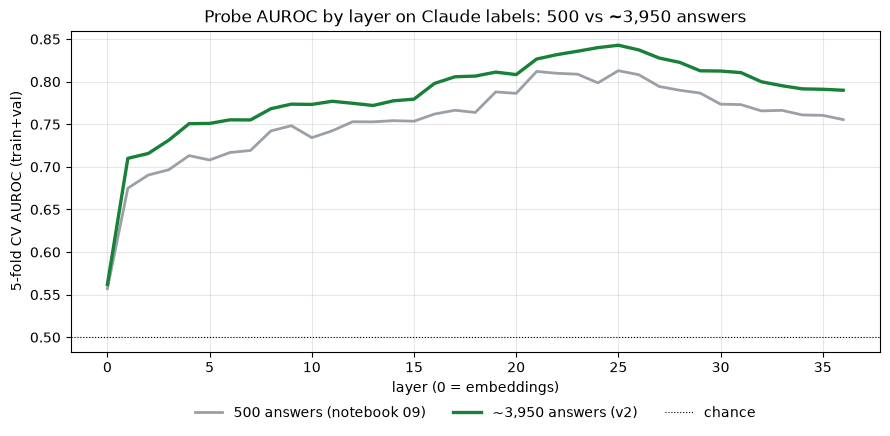

In [5]:
old = pd.read_csv(config.RESULTS_DIR / 'layer_sweep_Qwen2.5-3B-Instruct_claude_labels.csv')
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(old['layer_index'], old['cv_auroc'], color='#9aa0a6', lw=2, label='500 answers (notebook 09)')
ax.plot(sweep['layer_index'], sweep['cv_auroc'], color='#188038', lw=2.4, label='~3,950 answers (v2)')
ax.axhline(0.5, color='black', lw=0.8, ls=':', label='chance')
ax.set_xlabel('layer (0 = embeddings)'); ax.set_ylabel('5-fold CV AUROC (train+val)')
ax.set_title('Probe AUROC by layer on Claude labels: 500 vs ~3,950 answers'); ax.grid(alpha=0.3)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
fig.tight_layout(); fig.savefig(config.RESULTS_DIR / f'layer_sweep_{tag}.png', dpi=150); plt.show()

## C · Improvement ablation

In [6]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.improve import best_over_C, C_GRID, layer_ensemble, auto_layer, average, stacked_with_uncertainty
from src.relabel import confident_only

avg = {rep: layer_average(getattr(d, rep), LATE) for rep in ('answer_last', 'answer_mean')}
feat = lambda X: (lambda i: X[i])
L16 = feat(d.answer_last[:, 16])

def lda(f):
    def fp(tr, te):
        m = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto'))
        return m.fit(f(tr), d.y[tr]).predict_proba(f(te))[:, 1]
    return fp

def mass_mean(f):
    def fp(tr, te):
        s = StandardScaler().fit(f(tr)); X = s.transform(f(tr)); y = d.y[tr]
        w = X[y == 1].mean(0) - X[y == 0].mean(0)
        z = s.transform(f(te)) @ w - (X @ w).mean()          # centre on the training scores
        return 1 / (1 + np.exp(-z / (np.std(X @ w) + 1e-9)))   # squash so p > 0.5 means 'hallucination'
    return fp

high = lambda make: (lambda C: confident_only(d, conf, HIGH, make(C)))
ablation = [
    ('Baseline: layer 16, last token', lambda C: linear_probe(d, L16, C), C_GRID),
    ('Layer 16 + high-confidence labels only', high(lambda C: linear_probe(d, L16, C)), C_GRID),
    ('Best single layer (nested CV)', lambda C: auto_layer(d, 'answer_last', C), [1e-3]),
    ('One probe per layer 18-36, averaged', lambda C: layer_ensemble(d, 'answer_last', LATE, C), [1e-3]),
    ('Layer-averaged state 18-36', lambda C: linear_probe(d, feat(avg['answer_last']), C), C_GRID),
    ('Answer mean, layer-averaged 18-36', lambda C: linear_probe(d, feat(avg['answer_mean']), C), C_GRID),
    ('Last + mean, averaged', lambda C: average(*[linear_probe(d, feat(avg[r]), C) for r in avg]), C_GRID),
    ('Uncertainty features alone', lambda C: linear_probe(d, feat(d.uncertainty), C), [0.01, 0.1, 1.0]),
    ('Layer-averaged + uncertainty (stacked)', lambda C: stacked_with_uncertainty(d, linear_probe(d, feat(avg['answer_last']), C)), [1e-3]),
    ('Layer-averaged, PCA 64 + LR', lambda C: linear_probe(d, feat(avg['answer_last']), C, pca=64), [1e-3, 1e-2, 1e-1]),
    ('Layer-averaged, shrinkage LDA', lambda C: lda(feat(avg['answer_last'])), [None]),
    ('Layer-averaged, mass-mean probe', lambda C: mass_mean(feat(avg['answer_last'])), [None]),
    ('Layer-averaged 18-36 + high-confidence labels', high(lambda C: linear_probe(d, feat(avg['answer_last']), C)), C_GRID),
]
rows = []
for name, make, Cs in ablation:
    C = best_over_C(d, make, Cs, repeats=1)['C'] if len(Cs) > 1 else Cs[0]
    r = record('C', name, make(C))
    rows.append({'candidate': name, 'C': C, **{k: v for k, v in r.items()}})
ablation_df = pd.DataFrame(rows)
ablation_df.to_csv(config.RESULTS_DIR / f'improvement_ablation_{tag}.csv', index=False)
ablation_df.drop(columns=['cv_auroc_std']).round(3)

,candidate,C,cv_auroc,cv_accuracy,val_accuracy,val_auroc,test_accuracy,test_balanced_accuracy,test_f1,test_auroc
0,"Baseline: layer 16, last token",0.001,0.796,0.720,0.715,0.764,0.758,0.746,0.690,0.843
1,Layer 16 + high-confidence labels only,0.001,0.790,0.717,0.700,0.749,0.761,0.752,0.699,0.858
2,Best single layer (nested CV),0.001,0.833,0.754,0.792,0.849,0.766,0.760,0.710,0.869
3,"One probe per layer 18-36, averaged",0.001,0.833,0.747,0.788,0.841,0.776,0.775,0.728,0.876
4,Layer-averaged state 18-36,0.001,0.813,0.733,0.768,0.829,0.755,0.755,0.707,0.855
5,"Answer mean, layer-averaged 18-36",0.001,0.807,0.731,0.739,0.800,0.780,0.775,0.728,0.864
6,"Last + mean, averaged",0.001,0.823,0.740,0.776,0.832,0.766,0.765,0.717,0.869
7,Uncertainty features alone,0.100,0.615,0.594,0.642,0.650,0.576,0.565,0.486,0.596
8,Layer-averaged + uncertainty (stacked),0.001,0.816,0.736,0.764,0.837,0.750,0.756,0.710,0.862
9,"Layer-averaged, PCA 64 + LR",0.001,0.792,0.716,0.746,0.795,0.734,0.742,0.695,0.845


## D · Model comparison (all model types + DualPositionNet)

In [7]:
from src.model_compare import model_zoo, sk_model
from src.relabel import DualPositionNet
from src.improve import cv_auroc

X = {'avg': avg['answer_last'], 'stack': d.answer_last[:, LATE],
     'dual': np.stack([d.answer_last[:, LATE], d.answer_mean[:, LATE]], 1)}
zoo = model_zoo()
zoo['Neural net: DualPositionNet (new)'] = {'family': 'neural', 'input': 'dual', 'grid': {
    f'h={h}': (lambda h=h: DualPositionNet(hidden=h, dropout=0.5, epochs=150, lr=3e-4)) for h in (64, 128)}}

rows = []
for name, spec in zoo.items():
    f = (lambda k: (lambda i: X[k][i]))(spec['input'])
    grid = {label: cv_auroc(d, sk_model(d, f, make), repeats=1)['cv_auroc'] for label, make in spec['grid'].items()}
    setting = max(grid, key=grid.get)
    r = record('D', name, sk_model(d, f, spec['grid'][setting]))
    rows.append({'model': name, 'family': spec['family'], 'setting': setting, **r})
zoo_df = pd.DataFrame(rows).sort_values('cv_auroc', ascending=False)
zoo_df.to_csv(config.RESULTS_DIR / f'model_comparison_{tag}.csv', index=False)
zoo_df.drop(columns=['cv_auroc_std']).round(3)

,model,family,setting,cv_auroc,cv_accuracy,val_accuracy,val_auroc,test_accuracy,test_balanced_accuracy,test_f1,test_auroc
11,Neural net: DualPositionNet (new),neural,h=64,0.847,0.766,0.810,0.874,0.797,0.786,0.739,0.877
10,Neural net: learned layer weights + MLP,neural,"h=64,epochs=200",0.844,0.765,0.795,0.861,0.788,0.784,0.739,0.872
9,Neural net: learned layer weights + linear,neural,epochs=200,0.832,0.754,0.790,0.847,0.758,0.760,0.713,0.869
8,"Neural net: MLP, 1 hidden layer",neural,"h=256,epochs=150",0.826,0.749,0.766,0.837,0.771,0.760,0.707,0.866
3,RBF-kernel SVM,kernel,C=1.0,0.821,0.700,0.764,0.838,0.775,0.721,0.621,0.859
0,Logistic regression (baseline),linear,C=0.001,0.813,0.733,0.768,0.829,0.755,0.755,0.707,0.855
6,Random forest,trees,max_features=0.1,0.808,0.724,0.754,0.813,0.787,0.769,0.716,0.865
4,k-nearest neighbours,instance,k=31,0.806,0.727,0.725,0.806,0.765,0.746,0.688,0.839
2,Linear SVM,linear,C=0.0001,0.802,0.716,0.766,0.816,0.800,0.769,0.710,0.857
1,"Logistic regression, L1 (sparse)",linear,C=0.1,0.793,0.716,0.751,0.816,0.723,0.721,0.667,0.809


## Everything in one table

In [8]:
summary = pd.DataFrame(summary_rows).drop_duplicates('model').sort_values('cv_auroc', ascending=False)
summary.to_csv(config.RESULTS_DIR / f'all_models_{tag}.csv', index=False)
(config.RESULTS_DIR / f'all_models_{tag}.json').write_text(json.dumps({
    'data': 'v2: all 790 TruthfulQA questions x 5 sampled answers (src/expand.py)', 'labels': 'Claude (src/llm_judge.py)',
    'answers': int(len(d.y)), 'questions': int(len(set(d.question_id))),
    'protocol': 'CV: grouped 5-fold on train+val x1. Val: fit train, score val. Test: fit train+val, score test once. Accuracy at p > 0.5. Settings picked by CV AUROC.',
    'best_layer_by_cv': best_cv_layer, 'models': summary.to_dict(orient='records')}, indent=2, default=float))
cols = ['part', 'model', 'cv_auroc', 'cv_accuracy', 'val_accuracy', 'val_auroc', 'test_accuracy', 'test_balanced_accuracy', 'test_auroc']
summary[cols].round(3)

,part,model,cv_auroc,cv_accuracy,val_accuracy,val_auroc,test_accuracy,test_balanced_accuracy,test_auroc
25,D,Neural net: DualPositionNet (new),0.847,0.766,0.810,0.874,0.797,0.786,0.877
24,D,Neural net: learned layer weights + MLP,0.844,0.765,0.795,0.861,0.788,0.784,0.872
3,C,Best single layer (nested CV),0.833,0.754,0.792,0.849,0.766,0.760,0.869
4,C,"One probe per layer 18-36, averaged",0.833,0.747,0.788,0.841,0.776,0.775,0.876
23,D,Neural net: learned layer weights + linear,0.832,0.754,0.790,0.847,0.758,0.760,0.869
22,D,"Neural net: MLP, 1 hidden layer",0.826,0.749,0.766,0.837,0.771,0.760,0.866
7,C,"Last + mean, averaged",0.823,0.740,0.776,0.832,0.766,0.765,0.869
17,D,RBF-kernel SVM,0.821,0.700,0.764,0.838,0.775,0.721,0.859
9,C,Layer-averaged + uncertainty (stacked),0.816,0.736,0.764,0.837,0.750,0.756,0.862
14,D,Logistic regression (baseline),0.813,0.733,0.768,0.829,0.755,0.755,0.855


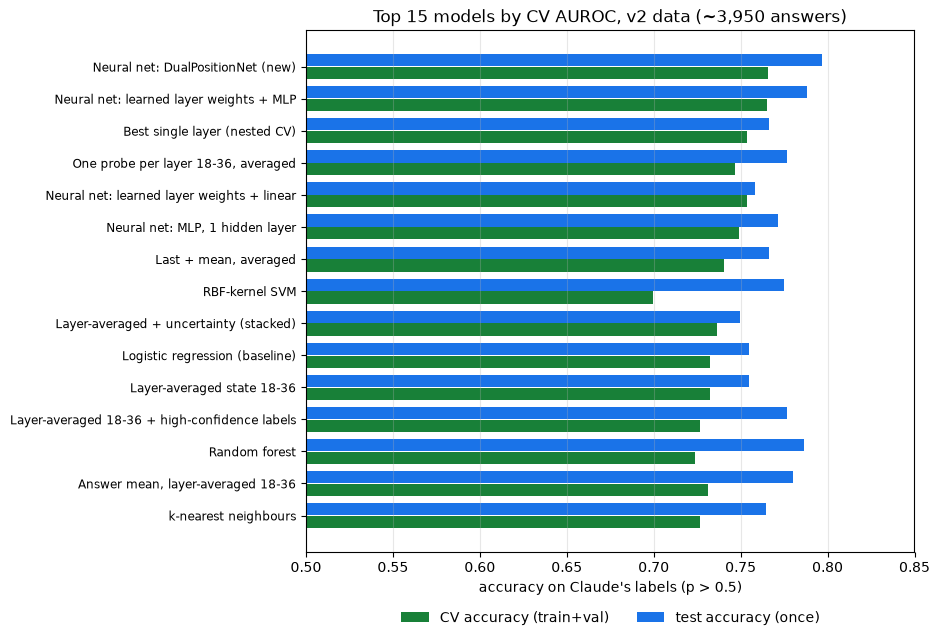

In [9]:
top = summary.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 6.5))
y = np.arange(len(top))
ax.barh(y - 0.2, top['cv_accuracy'], height=0.38, color='#188038', label='CV accuracy (train+val)')
ax.barh(y + 0.2, top['test_accuracy'], height=0.38, color='#1a73e8', label='test accuracy (once)')
ax.set_yticks(y); ax.set_yticklabels(top['model'], fontsize=8.5)
ax.set_xlim(0.5, 0.85); ax.set_xlabel("accuracy on Claude's labels (p > 0.5)")
ax.set_title('Top 15 models by CV AUROC, v2 data (~3,950 answers)'); ax.grid(axis='x', alpha=0.3)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=2, frameon=False)
fig.tight_layout(); fig.savefig(config.RESULTS_DIR / f'all_models_{tag}.png', dpi=150); plt.show()

## v2 vs notebook 09 (500 answers)
Same models and settings. The `_500` columns are notebook 09's numbers. The test sets differ (75 vs ~595 answers), and v2's is much larger, so its test numbers are the more reliable.

In [10]:
nb9 = pd.read_csv(config.RESULTS_DIR / 'all_models_Qwen2.5-3B-Instruct_claude_labels.csv').set_index('model')
both = summary.set_index('model')[['cv_auroc', 'cv_accuracy', 'val_accuracy', 'test_accuracy', 'test_auroc']].join(
    nb9[['cv_auroc', 'cv_accuracy', 'val_accuracy', 'test_accuracy', 'test_auroc']], rsuffix='_500')
both['cv_accuracy_gain'] = both['cv_accuracy'] - both['cv_accuracy_500']
both.sort_values('cv_auroc', ascending=False).round(3)

/var/folders/x6/fbfnyk851zzfzzz8gb5v94lc0000gn/T/ipykernel_57172/3027549773.py:2: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  both = summary.set_index('model')[['cv_auroc', 'cv_accuracy', 'val_accuracy', 'test_accuracy', 'test_auroc']].join(


,cv_auroc,cv_accuracy,val_accuracy,test_accuracy,test_auroc,cv_auroc_500,cv_accuracy_500,val_accuracy_500,test_accuracy_500,test_auroc_500,cv_accuracy_gain
model,,,,,,,,,,,
Neural net: DualPositionNet (new),0.847,0.766,0.810,0.797,0.877,0.790,0.722,0.787,0.680,0.729,0.044
Neural net: learned layer weights + MLP,0.844,0.765,0.795,0.788,0.872,0.796,0.747,0.800,0.707,0.738,0.019
Best single layer (nested CV),0.833,0.754,0.792,0.766,0.869,0.796,0.741,0.827,0.693,0.742,0.013
"One probe per layer 18-36, averaged",0.833,0.747,0.788,0.776,0.876,0.789,0.734,0.800,0.720,0.768,0.013
Neural net: learned layer weights + linear,0.832,0.754,0.790,0.758,0.869,0.787,0.718,0.773,0.693,0.718,0.036
"Neural net: MLP, 1 hidden layer",0.826,0.749,0.766,0.771,0.866,0.768,0.707,0.720,0.667,0.698,0.042
"Last + mean, averaged",0.823,0.740,0.776,0.766,0.869,NaN,NaN,NaN,NaN,NaN,NaN
RBF-kernel SVM,0.821,0.700,0.764,0.775,0.859,0.762,0.653,0.707,0.680,0.715,0.047
Layer-averaged + uncertainty (stacked),0.816,0.736,0.764,0.750,0.862,0.770,0.705,0.707,0.693,0.732,0.031
